In [1]:
from iorsimlib import runsim
from pathlib import Path
from ECLlib import IX_input
home = Path.home()
shared = Path('/home/shared/owner')
cases = home/'github/IORSim_GUI/cases'
iorsim = home/'github/IORSim'
iorexe = iorsim/'build/bin/IORSimX'

#root = shared/'CoP_files/input/CF6_IORSIM_AH/CF6_IORSIM'
#root = shared/'CoP_files/input/IORSIM_BASECASE_TRACER/IORSIM_BASECASE_INPUT'
#root = shared/'CoP_files/input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
#root = shared/'CoP_files/output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
root = cases/'Model_From_IXF/Model_From_IXF'
#root = '/media/javi/LaCie/ekofisk/input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT.afi'

ix = IX_input(root)
#list(ix.nodes('Recurrent3DReport', context=True, table=True))
#ix.UNRST_settings().get('Unified')
#ix.write_unified_UNRST()
#ix.afi
#[m for m in ix.afi.matches() if m[2] and b'restart' in m[2]]
#------ IX ------
runsim(root=root, iorexe=iorexe, only_host=True, intersect=1, nproc=1, nice=19);
#------ IORSim ------
#runsim(root=root, iorexe=iorexe, only_iorsim=True, merge=True);
#------ IX + IORSim ------
#runsim(root=root, iorexe=iorexe, intersect=1, nproc=1, nice=19);
#------ ECL + IORSim ------
#runsim(root=root, only_iorsim=True, iorexe=iorexe);
#IX_input(root).report_dates()



    Case      : Model_From_IXF
    Mode      : Intersect
    Days      : 1096.0
    Run-dir   : /home/AD.NORCERESEARCH.NO/javi/github/IORSim_GUI/notebooks
    Case-dir  : /home/AD.NORCERESEARCH.NO/javi/github/IORSim_GUI/cases/Model_From_IXF
    Log-files : /home/AD.NORCERESEARCH.NO/javi/github/IORSim_GUI/cases/Model_From_IXF/intersect.log
              : /home/AD.NORCERESEARCH.NO/javi/github/IORSim_GUI/cases/Model_From_IXF/ior2ecl.log
    Version   : 4.0.2.dev0+g58ee6d1.d20250618
    Started   : 2025-06-19 15:33:39


   Starting Intersect...                                                           'nice' (391278)
   ERROR 'nice' (391278) disappeared while searching for child-processes!          



In [36]:
from ior2ecl import Output
out = Output(root)
sec = out.slb_unrst.section_blocks()
unrst = out.slb_unrst
#startpos = unrst.section_filepos() #[b.startpos for s,b in unrst.blocks_matching('SEQNUM')]
header_pos = list(unrst.section_slices(('SEQNUM', 'startpos'), ('STARTSOL', 'endpos')))
#unrst.end_step()

In [38]:
from IORlib.ECL import File, UNRST_file
from itertools import islice
header_pos[100][1]
# Get progress of nohup-runs in the background 
#out = Output(root)
#unrst = out.slb_unrst
#startpos = [b.startpos for s,b in unrst.blocks_matching('SEQNUM')]
#for n, bl in unrst.blocks_matching('SEQNUM', 'STARTSOL', start=startpos[-1]):
#    print(bl.data())

#list(unrst.blockdata('SEQNUM'))[-1]
#next(unrst.blocks(start=startpos[1000]))
#next(unrst.section_blocks(start=2000))
# def write_data(step):
#     start = ('SEQNUM', 'startpos')
#     end = ('STARTSOL', 'endpos')
#     data = unrst.section_data(start, end, begin=step)
#     file = UNRST_file('tester')
#     with open(file.path, 'ab') as f:
#         step, data = next(unrst.section_data(start, end, begin=step))
#         print(len(byts))
#         f.write(byts)
# next(unrst.section_data(start=start, end=end, begin=0))
#write_data()
#len(data)
#data = list(islice(secdata, None))

#out.slb_unrst.end_date()
#ior_dates = list(out.ior_unrst.dates())
#len(ior_dates), ior_dates[-1]
#out.merge(force=True)

slice(18063488516, 18065751188, None)

In [10]:
next(file.section_blocks())

(<key=SEQNUM  , type=INTE, bytes=       4,length=       1, start=       0, end=      36>,
 <key=INTEHEAD, type=INTE, bytes=    1644,length=     411, start=      36, end=    1712>,
 <key=LOGIHEAD, type=LOGI, bytes=     400,length=     100, start=    1712, end=    2144>,
 <key=DOUBHEAD, type=DOUB, bytes=    1296,length=     162, start=    2144, end=    3472>,
 <key=STARTSOL, type=MESS, bytes=       0,length=       0, start=    3472, end=    3496>)

In [ ]:
from IORlib.ECL import unfmt_file
gsg = unfmt_file('IXF_Examples/Tracers/Tracers.EGRID')
for b in gsg.blocks():
    print(b)

IORSIM_BASECASE_INPUT_TRACER_CONCENTRATION.GSG
0 ('p',) ('TRACER_CONCENTRATION["EKO"]',) TREKO (210, 266, 23)
0 ('p',) ('TRACER_CONCENTRATION["TOR"]',) TRTOR (210, 266, 23)
--------------------------------------------------


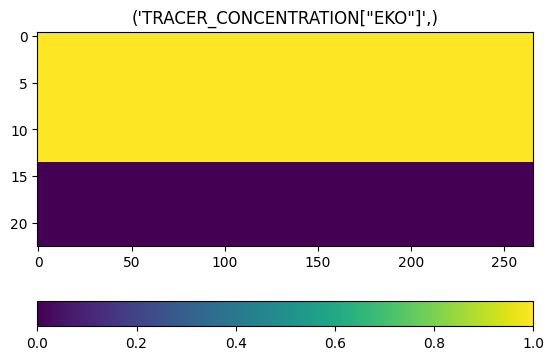

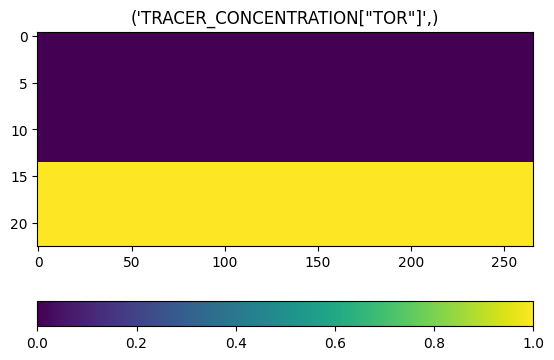

In [5]:
from math import prod
from pathlib import Path
import numpy as np
from IORlib.ECL import INIT_file
from IORlib.GSG import PROP_data, read_prop_file, File, write_prop_file
from matplotlib import pyplot as pl

home = Path.home()
input = Path('/home/shared/owner/CoP_files/input')
#root = input/'Tracers/Tracers'
root = input/'IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

files = [
    Path(f'{root}_CONNATE_WATER_SATURATION.GSG'),
    Path(f'{root}_FLUID_IN_PLACE_REGION.GSG'),
    Path(f'{root}_CRITICAL_WATER_SATURATION.GSG'),
    Path(f'{root}_POROSITY.GSG'),
    Path(f'{root}_MAX_WATER_SATURATION.GSG'),
    Path(f'{root}_TRACER_CONCENTRATION.GSG'),
    Path(f'{root}_REGIONS.GSG'),
    Path(f'{root}_PERM_I.GSG'),
    Path(f'{root}_RESIDUAL_OIL_SATURATION_TO_WATER_IMBIBITION.GSG'),
    Path(f'{root}_RESIDUAL_OIL_SATURATION_TO_WATER.GSG')
]

#files = list(root.parent.glob('*.GSG'))

dim = INIT_file(root).dim()
#dim = (3,3,3)
eko = np.zeros(dim, dtype=np.float32)
eko[:, :, :14] = 1
tor = np.zeros(dim, dtype=np.float32)
tor[:, :, 14:] = 1
ceko = PROP_data('p', 'TRACER_CONCENTRATION["EKO"]', 'TREKO', eko, 0)
ctor = PROP_data('p', 'TRACER_CONCENTRATION["TOR"]', 'TRTOR', tor, 0)
write_prop_file(Path(f'{root}_TRACER_CONCENTRATION.GSG'), ceko, ctor)

for file in files[5:6]:
    print(file.name)
    for data in read_prop_file(file, dim=dim):
        print(data.kind, data.type, data.name, data.alias, data.array.shape)
        #print(data.array[:5], data.array[-5:])
        pl.figure()
        pl.title(data.name)
        pl.imshow(data.array[100, :, :].T, origin='upper', aspect=5, interpolation='none')
        pl.colorbar(orientation='horizontal')
    print(50*'-')



In [12]:
import numpy as np
from itertools import chain

arr = np.array([2.0, 2.0, 2.0, 2.0, 3, 3, 3, 4, 4])

# Create a mask detecting changes in consecutive elements
mask = np.concatenate(([True], arr[:-1] != arr[1:]))
# Compute run lengths
counts = np.diff(np.where(np.append(mask, True))[0])  
# Stack counts and unique values
[1] + list(chain.from_iterable(zip(counts, arr[mask])))
#compressed = np.column_stack((counts, arr[mask])).flatten()
#[1] + [int(n)]

[1, 4, 2.0, 3, 3.0, 2, 4.0]

In [ ]:
from IORlib.ECL import RFT_file, UNRST_file, UNSMRY_file
from ior2ecl import IORSim_output
#import matplotlib.pyplot as pl
#%matplotlib widget
#pl.close('all')
#out = Output(root)
#out.slb_unrst.end_date()
rft = RFT_file(root)
#unrst = UNRST_file(root)
next(rft.section_blocks())
#list(unrst.section_blocks())[:2]
#ior = IORSim_output(root)
#smry = UNSMRY_file(root)
#smry.welldata()
#smry.wells
#smry.plot(wells=('B21',))


In [ ]:
root1 = shared/'CoP_files/output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
out1 = Output(root1)
#print('IOR', list(out1.ior_unrst.dates())[-1])
root2 = shared/'CoP_files/input/IORSIM_BASECASE_INCOMP/IORSIM_BASECASE_INPUT'
out2 = Output(root2)
print('IOR', list(out2.ior_unrst.dates())[-1])


In [ ]:
from IORlib.ECL import File, IX_input
from IORlib.utils import flatten
from ior2ecl import IORSim_input
ix = IX_input(root)
files = (file for file in ix.include_files() if not file.suffix == '.GSG')
data = ''.join(data.decode() for file in files if b'C03' in (data:=File(file).binarydata()))

#inj_ix = sorted(w[0] for w in ix.wells() if 'GAS' in w[1])
#len(inj_ix)
#ior = IORSim_input(root)
#inj_ior = list(flatten(ior.get('INJECTOR')))
#set(inj_ix) - set(inj_ior)

#welldef = [node.name for node in ix.nodes('WellDef')]
#well = [node for node in ix.nodes('Well')]
#well

In [ ]:
ix = IX_input(root)
# List producers
#prod = [w[0] for w in inp.wells() if w[1]=='PRODUCER']
#print(len(prod))
#print('\n'.join(sorted(prod)))
# List injectors
inj = [f'{w[0]} 1 0.0 1.0 25'  for w in ix.wells() if w[1]=='WATER_INJECTOR']
print(len(list(inj)))
print('\n'.join(sorted(inj)))


In [ ]:
from IORlib.utils import daterange
dates = (f'DATE "{date}"' for date in daterange((1971, 7, 1), 100, step=7, format='%d-%b-%Y'))
print('\n'.join(dates))

In [ ]:
#from ior2ecl import Output
from pathlib import Path
import numpy as np
from datetime import datetime
from IORlib.ECL import UNRST_file
home = Path.home()
shared = Path('/home/shared/owner')
cases = home/'github/IORSim_GUI/cases'

def write(file, name, index, values, max=None, min=None):
    if max:
        txt = 'max:'
        maxmin = np.max
    if min:
        txt = 'min:'
        maxmin = np.min
    data = [values[tuple(i)] for i in index]
    limval = f'{txt} {maxmin(data):9.5f}' if len(index) else ''
    hist = f'hist: {'|'.join(f'{a: 4d},{b:11.3e}' for a,b in zip(*np.histogram(data)))}'
    file.write(f'   {name}')
    file.write(f'      {len(index): 5d} blocks, {limval}\n')
    file.write(f'      {hist}\n')

#root = shared/'CoP_files/input/CF6_IORSIM_AH/CF6_IORSIM'
#root = shared/'CoP_files/input/IORSIM_BASECASE_ITER2/IORSIM_BASECASE_INPUT'
#root = shared/'CoP_files/input/IORSIM_BASECASE/IORSIM_BASECASE_INPUT'
root = shared/'CoP_files/input/IORSIM_BASECASE_INCOMP/IORSIM_BASECASE_INPUT'
#root = shared/'CoP_files/output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'

unrst = UNRST_file(root)
#next(unrst.section_blocks())
low = 1.42315
high = 3.33013
sea = 0.56187
low = sea
err = 1e-2
n = 0
with open(root.with_suffix('.limit_check'), 'w') as file:
    for arr in unrst.cellarray('CL','RPORV', step=1):
        cl = arr.cl[0,...]
        below = np.array(np.where(cl < low-err)).T
        above = np.array(np.where(cl > high+err)).T
        file.write(f'{arr.dates[0]}\n')
        write(file, 'Below', below, cl, min=True)
        write(file, 'Above', above, cl, max=True)
        #print(arr.dates[0], 'below:', len(below), len(below)>0 and np.min([cl[tuple(i)] for i in below]), 'above:', len(above), len(above)>0 and np.max([cl[tuple(i)] for i in above]))
        #file.write('   Below:', len(below), f'{np.min([cl[tuple(i)] for i in below]):.5f}' if len(below) else '', '\n')
        #file.write('   Above:', len(), f'{np.min([cl[tuple(i)] for i in below]):.5f}' if len(below) else '', '\n')
        #print(arr.rporv[below])
        #print(below,'\n', above)
        n += 1
        # if n > 3:
        #     break

# (210, 266, 23)
# []
# 1971-07-01 00:00:00 below: 0 False above: 0 False
# (210, 266, 23)
# []
# 1971-08-01 00:00:00 below: 0 False above: 0 False
# (210, 266, 23)
# [array([74, 89, 18]), array([ 74, 116,  15]), array([ 74, 120,  14]), array([ 75, 127,  14]), array([100,  65,  14])]
# 1971-09-01 00:00:00 below: 0 False above: 5 3.3597371578216553
# (210, 266, 23)
# [array([74, 89, 18]), array([ 74, 116,  15]), array([ 74, 120,  14]), array([ 75, 127,  14]), array([90, 65, 14]), array([90, 65, 15])]
# 1971-10-01 00:00:00 below: 1 0.5496221780776978 above: 6 3.483799695968628


In [ ]:
cl[tuple(np.array([170, 212,  15]))]
#cl[170,212,15]

In [ ]:
import matplotlib.pyplot as pl
from IORlib.ECL import UNRST_file
from pathlib import Path
import numpy as np

psi2pa = 6894.75729
Cw = 4.0e-10 # Pa-1, water compressibility
Co_psi = 8e-6 # psi-1, oil compressibility
Co_pa = 8e-6/psi2pa # Pa-1, oil compressibility


home = Path.home()
shared = Path('/home/shared/owner')
root1 = shared/'CoP_files/input/IORSIM_BASECASE_INCOMP/IORSIM_BASECASE_INPUT'
#root1 = shared/'CoP_files/input/IORSIM_BASECASE_TRACER/IORSIM_BASECASE_INPUT'
#root1 = shared/'CoP_files/input/IORSIM_BASECASE/IORSIM_BASECASE_INPUT'
root2 = shared/'CoP_files/input/IORSIM_BASECASE_2/IORSIM_BASECASE_1971TO2022'
#unrst = UNRST_file(root)
low = 1.42315
high = 3.33013
sea = 0.56187
# Modify the default colormap
#jet = pl.colormaps['jet']
#colors = jet(np.linspace(0, 1, 41))
#pl.rcParams['axes.prop_cycle'] = pl.cycler(color=colors) #=('b',)+colors[1:]) 

def read(root, vars, stop=None):
    unrst = UNRST_file(root)
    dates = list(unrst.dates())[:stop]
    vals = ([getattr(arr, var.lower())[0][cell] for var in vars] for arr in unrst.cellarray(*vars, step=1, stop=stop))
    return dates, *[np.array(v) for v in zip(*vals)]

cell = (141, 92, 9)
#stop = None
#rporv, cl = zip(*((arr.rporv[0][cell], arr.cl[0][cell]) for arr in unrst.cellarray('RPORV', 'CL', 'SOIL', step=1, stop=stop)))
#vars = ('RPORV', 'CL', 'PRESSURE')
specie = 'TRACER1' # 'CL'
vars = ('RPORV', specie, 'PRESSURE')
dates1, rporv1, conc1, pres1 = read(root1, vars)
#dates2, rporv2, cl2, pres2 = read(root2, vars)
pl.close('all')
# Concentration / Pressure
fig = pl.figure(1)
ax1 = fig.subplots(1,1)
ax1.set_title(f'Block {cell}+1')
ax1.plot(dates1, conc1, 'go-', label=specie)
ax1.set_ylabel('Concentration [mol/L]')
ax1.set_xlabel('Dates')
ax2 = ax1.twinx()
pres_pa = pres1*psi2pa
ax2.plot(dates1, pres_pa*1e-6, 'ro--', label='Pressure')
ax2.set_ylabel('Pressure [MPa]')
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
pl.legend(h1+h2, l1+l2)
pl.savefig(f'{specie}_G02X.png')
# Concentration / Water volume change
fig = pl.figure(11)
ax1 = fig.subplots(1,1)
ax1.set_title(f'Block {cell}+1')
ax1.plot(dates1, 100*(conc1-conc1[0])/conc1[0], 'go-', label=specie)
ax1.set_ylabel('Concentration change [%]')
ax1.set_xlabel('Dates')
ax2 = ax1.twinx()
ax2.plot(dates1, 100*(pres_pa-pres_pa[0])*Cw, 'bo--', label='water')
ax2.plot(dates1, 100*(pres_pa-pres_pa[0])*Co_pa, 'ro--', label='oil')
pl.text(0.05, 0.05, f'Cw = {Cw:.2e} 1/Pa', transform=ax1.transAxes)
pl.text(0.05, 0.1, f'Co = {Co_pa:.2e} 1/Pa', transform=ax1.transAxes)
#ax2.plot(dates1, 100*(pres1-pres1[0])*Co_psi, 'ro--', label='oil')
ax2.set_ylabel('Volume change [%]')
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
pl.legend(h1+h2, l1+l2)
pl.savefig(f'{specie}_volchange_G02X.png')
# 
fig = pl.figure(2)
ax1 = fig.subplots(1,1)
ax1.set_title(f'Block {cell}+1')
ax1.plot(dates1[1:], conc1[1:]-conc1[:-1], 'o-')
#ax1.plot(dates2[1:], cl2[1:]-cl2[:-1], 'o-')
ax1.set_ylabel('conc(t+1) - conc(t)')
ax1.set_xlabel('Date')
ax2 = ax1.twinx()
ax2.set_ylabel('100*(RPORV(t+1) - RPORV(t)) / RPORV(t)')
ax2.plot(dates1[1:], 100*(rporv1[1:]-rporv1[:-1])/rporv1[:-1], 'ro--', ms=5, mfc='None')
pl.savefig('Block_142_93_10_RPORV.png')
#
fig = pl.figure(3)
ax1 = fig.subplots(1,1)
ax1.set_title(f'Block {cell}+1')
ax1.plot(dates1[1:], 100*(conc1[1:]-conc1[:-1])/conc1[:-1], 'o-')
ax1.set_ylabel('100*(conc(t+1) - conc(t)) / conc(t)')
ax1.set_xlabel('Date')
ax2 = ax1.twinx()
ax2.set_ylabel('100*(PRESSURE(t+1) - PRESSURE(t)) / PRESSURE(t)')
ax2.plot(dates1[1:], 100*(pres1[1:]-pres1[:-1])/pres1[:-1], 'ro--', mfc='None')
#ax2.plot(dates1[1:], pres1[1:], 'ro--', mfc='None')
pl.savefig('Block_142_93_10_PRESSURE.png')


In [ ]:
C1 = 4.4e-10 # Pa-1
C2 = 3.9e-10 # Pa-1
100*100e6*C2

In [ ]:
%matplotlib widget
#from ior2ecl import runsim
from IORlib.ECL import UNSMRY_file
from pathlib import Path
home = Path.home()
shared = Path('/home/shared/owner')
#root = shared/'norne/NORNE_INTERSECT'
root = shared/'CoP_files/input/IORSIM_BASECASE/IORSIM_BASECASE_INPUT'
smry = UNSMRY_file(root)
#%timeit smry.welldata()
smry.plot(keys=('WOPR','WWPR','WWIR','WGIR'), wells=('G02X',))

In [ ]:
from IORlib.utils import first_index
#data = smry.welldata(keys=('FOPR','FWPR','FWIR','FGIR'), named=True)
data = smry.welldata(keys=('WWIR','WWPR'))
#a = data.values[0]
#sum(a.data) == 0
active = [val for val in data.values if val.key=='WWPR' and sum(val.data) > 0]
start_ind = [first_index(lambda x:x>0, act.data) for act in active]
start = [data.dates[i] for i in start_ind]
active[0].well
#list(zip(active[0].data, data.dates))

In [ ]:
from ior2ecl import Output
from IORlib.ECL import INIT_file, UNRST_file, IX_input, UNSMRY_file, RFT_file, SMSPEC_file
from IORlib.utils import tail, batched, flatten
from pathlib import Path
from operator import floordiv, sub
from itertools import starmap, chain, repeat
home = Path.home()
shared = Path('/home/shared/owner')
root = shared/'CoP_files/input/IORSIM_BASECASE/IORSIM_BASECASE_INPUT'
#root = shared/'norne/NORNE_INTERSECT'
#root = home/'github/IORSim_GUI/cases/GEOCHEM_BACK/GEOCHEM_BACK'
#root = home/'github/IORSim_GUI/cases/EKOFISK_HAUKAAS_2014_BACK/EKOFISK_HAUKAAS_2014_BACK'
#root = shared/'CoP_files/input/IORSIM_BASECASE_ITER3/IORSIM_BASECASE_INPUT'
#root = shared/'CoP_files/output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
#root = shared/'CoP_files/input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
#out = Output(root)
#out.convert();
#out.merge();

unrst = UNRST_file(root)
rft = RFT_file(root)
smry = UNSMRY_file(root)
spec = SMSPEC_file(root)
n = 0
for b in unrst.blocks():
    print(b)
    print(b.data(0,1))
    n += 1
    if n>1:
        break
next(spec.blockdata('STARTDAT'))
next(unrst.read2('nwell', tail=True))
print(list(rft.read2('time')))
smry.welldata();
next(unrst.blockdata('INTEHEAD', 0, 'INTEHEAD', 3, 5, 'INTEHEAD', 20, 30 )) 
list(unrst.blockdata('SEQNUM', 0))
unrst.count_sections()
next(unrst.blockdata('SEQNUM', 0, 'INTEHEAD', 0, 2, 'INTEHEAD', 6, 10)) 
next(unrst.blockdata('ZWEL'))
next(unrst.blockdata('INTEHEAD', 0, 10, 'ZWEL'))
list(unrst.read2('step', 'day', 'year', 'month'))
list(unrst.read2('step', only_new=True))
D = next(smry.blockdata('PARAMS', 2, 2999))
len(D)


In [ ]:
from IORlib.utils import pad
A = (0,5)
pad(A, 2, fill=A[0]+1)


In [ ]:
from IORlib.utils import pairwise, batched
from operator import sub

def group_indices(A):
    jumps = (p for p in pairwise(A) if -sub(*p)>1)
    return ((a, b+1) for a,b in batched(chain([A[0]], *jumps, [A[-1]]), 2))

A = (1,2,3,7,12,20,21,22)
B = list(range(30))
[B[slice(*s)] for s in group_indices(A)]



In [ ]:
from operator import floordiv
from itertools import starmap
a,b = 2, 10
list(starmap(floordiv, [(i,2) for i in (a,b)])) 

In [ ]:
from itertools import islice, chain
from IORlib.utils import pairwise, sliding_window, batched, flatten
from operator import sub
A = (1,2,3,4,5,8,9,12,13,14,15,20,21)
#ind = chain((i for i,a in enumerate(pairwise((0,)+A)) if -sub(*a)>1),[len(A)])
#ind = (i for i,a in enumerate(pairwise((0,)+A+(A[-1]+2,))) if -sub(*a)>1)
#ind = list(i+1 for i,a in enumerate(pairwise(A)) if -sub(*a)>1)
jumps = flatten(p for p in pairwise(A) if -sub(*p)>1)
#jumps = filter(lambda p:-sub(*p)>1, pairwise(A))
list(jumps)
#slices = batched(chain([A[0]], jumps, [A[-1]]), 2) 
#print(list(slices))
#[(A[a],A[b-1]) for a,b in sliding_window(chain([0], ind, [len(A)]), 2)]
#list(sliding_window(ind+[ind[-1]], 2))


In [ ]:
from itertools import islice
from IORlib.utils import flatten, batched
from IORlib.ECL import UNRST_file, SMSPEC_file
from pathlib import Path

home = Path.home()
shared = Path('/home/shared/owner')
root = shared/'CoP_files/input/IORSIM_BASECASE/IORSIM_BASECASE_INPUT'

unrst = UNRST_file(root)
a, b, c = next(unrst.blockdata('INTEHEAD', 66, 68, 'INTEHEAD', 64, 'SEQNUM'))
print(a, b, c)
spec = SMSPEC_file(root)
spec.welldata()
for b in UNRST_file(root).blocks():
   if 'PRESSURE' in b:
       break
   print(b)
   print(list(enumerate(b.data())))
#slices, = file_slices(P.header) #, [(990,4100),(0,100)])
#len(slices)
# [[3524, 7524]]
# [[3524, 7524], [7532, 11532]]
# [slice(7484, 7524, None), slice(7532, 7932, None)]

In [ ]:
from IORlib.utils import flatten_all
B = [('INTEHEAD', [64, 65]), ('INTEHEAD', [66, 68]), ('SEQNUM', [None])]
list(f'{b[0]}_{b[1][0]}' for b in B)

In [ ]:
from itertools import chain, groupby
from IORlib.utils import pairwise, pad, batched_when, flatten, batched

A = ('D', 10, 20, 'A', 4, 6, 'A', 2, 'B', 3, 'B', 1, 'C')
#A = ('A', 4, 6, 'A', 2)
batch = (batched_when(A, lambda x: isinstance(x, str)))
B = (pad(a, min(len(a)+1,3), fill=a[1]+1 if len(a)==2 else None) for a in batch)
B = ((a,b) for a,*b in B)
# Group on keywords
groups = ((k, list(zip(*sorted(g)))) for k,g in groupby(B, lambda x:x[0]))
key, lims = zip(*groups)
#print(key, lims)
if len(set(key)) != len(key):
    print('DUPLICATE', key)
# Merge limits: [4,6],[2,3] -> [2,6]
lims = [list(flatten(l[1])) for l in lims]
index = list(batched( flatten([None if l is None else l-ll[0] for l in ll] for ll in lims), 2))
lims = [None if l[0] is None else (l[0], l[-1]) for l in lims]
key, lims, index
#B
#dict(zip(*B))


In [ ]:
from IORlib.ECL import INIT_file, UNSMRY_file, SMSPEC_file, IX_input, DATA_file, UNRST_file
from pathlib import Path
from collections import namedtuple
import numpy as np
home = Path.home()
shared = Path('/home/shared/owner')
root = shared/'CoP_files/input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

#file = IX_input(root)
#print(file.start())
new = UNRST_file(root.with_name('IORSIM_BASECASE_INPUT_IORSim_PLOT.UNRST'))
ref = UNRST_file(root.with_name('IORSIM_BASECASE_INPUT_IORSim_surfrates.UNRST'))
#a,b = next(ref.blockdata('CL','_CL'))
#b
for (a,b),(b,*_) in zip(ref.blockdata('CL','SEQNUM'), new.blockdata('CL')):
    a = np.array(a)
    b = np.array(b)
    diff = 100*(a - b)/(0.5*(a+b))
    pos = np.where(abs(diff) > 10)
    print(b[0], pos[0])
    print('    a:', a[pos])
    print('    b:', b[pos])
    #if abs(sum(diff)) > 0:
    #    print(n[0], sum(diff), a[10000], b[10000])
    
#list(file.dates())
#for block in ref.blocks():
#    print(block)


In [ ]:
from pathlib import Path
from ior2ecl import FUNRST_file, UNRST_file, IX_input
home = Path.home()
root = home/'github/IORSim_GUI/cases/GEOCHEM_BACK/GEOCHEM_BACK'
#root = home/'EKOFISK_BASECASE_FELIX/IORSIM_BASECASE'
unrst = UNRST_file(root)
for block in unrst.blocks():
    print(block)

In [ ]:
from IORlib.ECL import IX_input
from pathlib import Path
shared = Path('/home/shared/owner')
root = shared/'CoP_files/input/IORSIM_BASECASE/IORSIM_BASECASE_INPUT'
#root = shared/'CoP_files/output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
ix = IX_input(root)
# list of (name, type) tuples
wells = [(well.name, type[0]) for well in ix.nodes('Well') if (type:=well.get('Type'))]
# separate lists of names and types
names, types = zip(*wells)
sorted(w for w,t in ix.wells() if t == 'PRODUCER')

